<a href="https://colab.research.google.com/github/hendav58-creator/FisicacomPhytonI/blob/main/TPRofZn_54.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Angular distribution of two-proton radioactivity


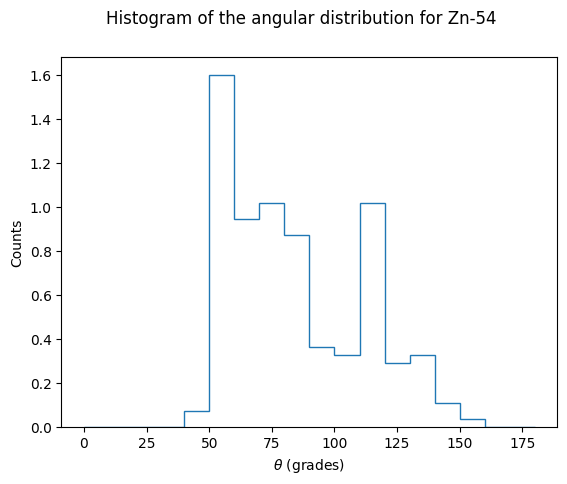

In [ ]:
# Two-proton radioactivity of Fe-45 and Zn-54
# and its angular distribution

# Code for Zn-54

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

import time
ini = time.time()

#Defining the data to be fitted

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180]
counts = [0, 0, 0, 0, 1, 22, 13, 14, 12, 5, 4.5, 14, 4, 4.5, 1.5, 0.5, 0, 0]

for i in range(0, 18):
   counts[i] = (1.6/22)*counts[i]

fig = plt.figure()

plt.hist(bins[:-1], bins, weights=counts, histtype='step')
plt.xlabel(r'$\theta$ (grades)')
plt.ylabel('Counts')
plt.suptitle('Histogram of the angular distribution for Zn-54')
plt.show()

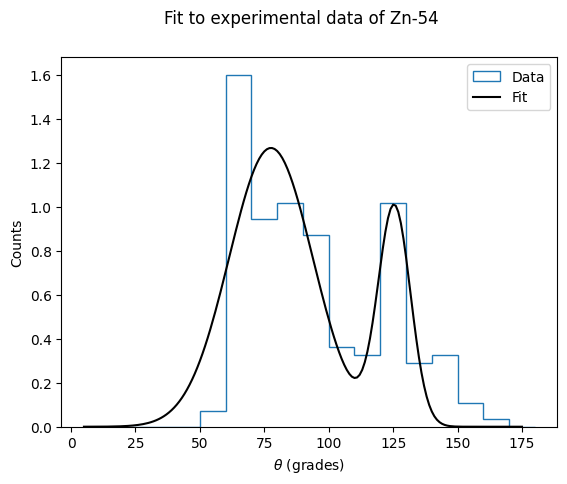

In [ ]:
# Defining the double gaussian to fit the histogram

def func(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def sumgauss(x, A1, mu1, sigma1, A2, mu2, sigma2):
    return func(x, A1, mu1, sigma1) + func(x, A2, mu2, sigma2)

# Defining xdata (bin centers) and ydata (counts) from the previous cell
bins = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180])
xdata = 0.5 * (bins[:-1] + bins[1:])
ydata = np.array(counts[:-1])

# Fit for the parameters A1, mu1, sigma1, A2, mu2, sigma2 of the double gaussian
# p0 needs 6 initial guesses corresponding to the 6 parameters of sumgauss
popt, pcov = curve_fit(sumgauss, xdata, ydata, p0=[20, 50, 20, 12, 140, 120])
xdata2 = np.linspace(5, 175, 171)

plt.hist(bins[:-1], bins, weights=counts[:-1], histtype='step', label='Data')
plt.plot(xdata2, sumgauss(xdata2, *popt), 'k-', label='Fit')
plt.xlabel(r'$\theta$ (grades)')
plt.ylabel('Counts')
plt.legend()
plt.suptitle('Fit to experimental data of Zn-54')
plt.show()